# 01 — Data loading and EDA (FD001)

Load the raw files, check the RUL label, look at the sensors and find the flat columns to remove.

In [1]:
import sys
sys.path.append("../src")
from load_data import ALL_SENSORS, FLAT_COLUMNS, SENSORS, SETTINGS, load_test, load_test_rul, load_train

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

train = load_train()
test = load_test()

## 1. Shapes

Train has 26 raw columns plus `rul`; test has the 26 raw columns only. Both have 100 engines and no missing values.

In [3]:
print("train:", train.shape, "| engines:", train["engine_id"].nunique())
print("test: ", test.shape, "| engines:", test["engine_id"].nunique())
print("missing values:", train.isna().sum().sum() + test.isna().sum().sum())

train: (20631, 27) | engines: 100
test:  (13096, 26) | engines: 100
missing values: 0


## 2. Engine lifetimes

The last cycle of each train engine is its lifetime. Lifetimes range from 128 to 362 cycles, so engines wear out at very different rates.

min 128, mean 206.31, max 362


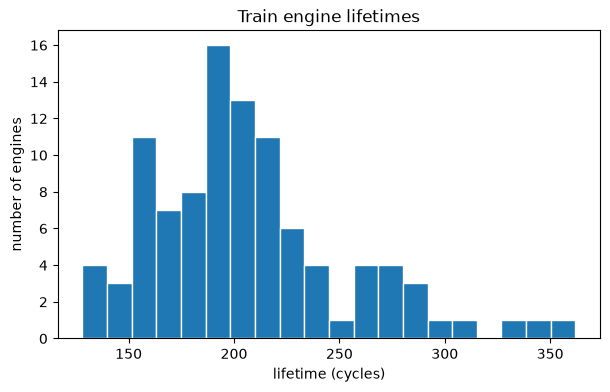

In [4]:
lifetimes = train.groupby("engine_id")["cycle"].max()
print(f"min {lifetimes.min()}, mean {lifetimes.mean():.2f}, max {lifetimes.max()}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(lifetimes, bins=20, edgecolor="white")
ax.set_xlabel("lifetime (cycles)")
ax.set_ylabel("number of engines")
ax.set_title("Train engine lifetimes")
plt.show()

## 3. RUL label

RUL = last cycle of the engine − current cycle. Engine 1 lasts 192 cycles, so its RUL starts at 191 and counts down to 0 at failure.

In [5]:
engine_1 = train.loc[train["engine_id"] == 1, ["engine_id", "cycle", "rul"]]
pd.concat([engine_1.head(3), engine_1.tail(3)])

,engine_id,cycle,rul
0,1,1,191
1,1,2,190
2,1,3,189
189,1,190,2
190,1,191,1
191,1,192,0


In [6]:
print("RUL is 0 at the last row of every engine:", (train.groupby("engine_id")["rul"].last() == 0).all())

RUL is 0 at the last row of every engine: True


## 4. Sensor trends

Four sensors against RUL for engines 1–5, with failure (RUL 0) on the right. The readings are flat and noisy for most of the life, then drift clearly in the last ~100 cycles before failure.

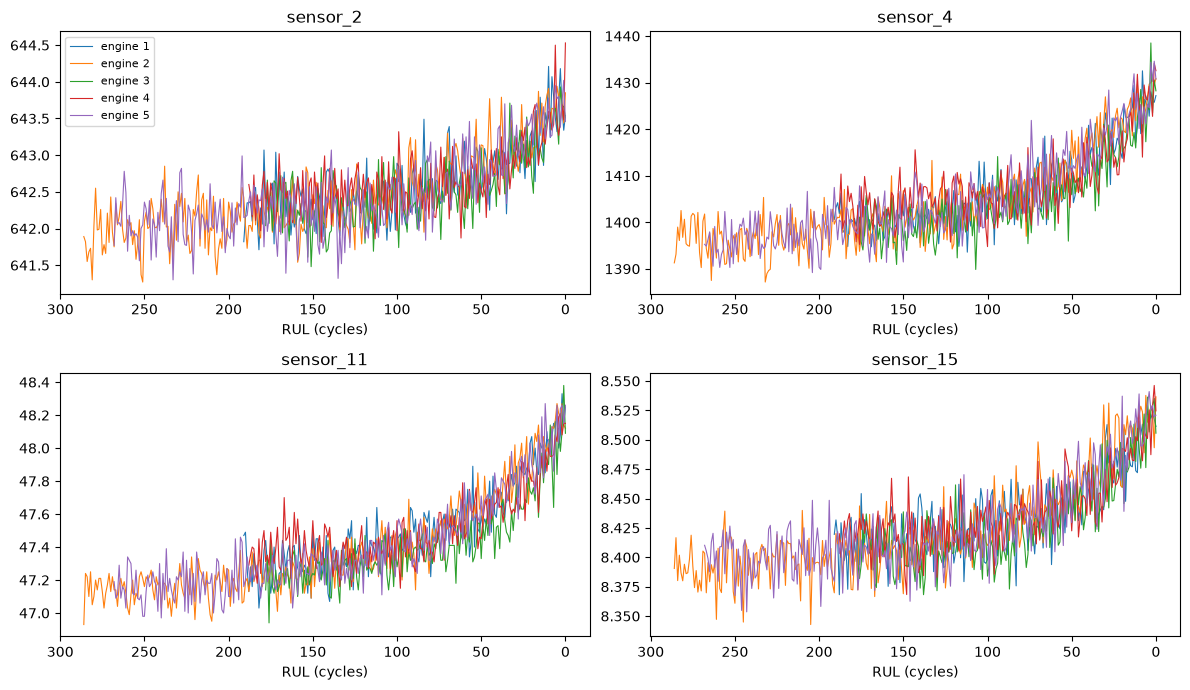

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, sensor in zip(axes.flat, ["sensor_2", "sensor_4", "sensor_11", "sensor_15"]):
    for engine_id in range(1, 6):
        e = train[train["engine_id"] == engine_id]
        ax.plot(e["rul"], e[sensor], linewidth=0.8, label=f"engine {engine_id}")
    ax.invert_xaxis()
    ax.set_title(sensor)
    ax.set_xlabel("RUL (cycles)")
axes[0, 0].legend(fontsize=8)
fig.tight_layout()
plt.show()

## 5. Flat columns

For each setting and sensor, the share of rows that have its most common value. A column is flat if the share is 0.95 or more: these 8 columns carry no information about wear. The next highest share is only 0.264, so the exact threshold doesn't matter.

In [8]:
shares = pd.Series(
    {col: train[col].value_counts(normalize=True).iloc[0] for col in SETTINGS + ALL_SENSORS},
    name="most_common_share",
).sort_values(ascending=False)
shares.round(3).to_frame()

,most_common_share
sensor_10,1.000
setting_3,1.000
sensor_1,1.000
sensor_19,1.000
sensor_18,1.000
sensor_5,1.000
sensor_16,1.000
sensor_6,0.980
sensor_17,0.264
setting_2,0.102


In [9]:
flat = shares[shares >= 0.95].index.tolist()
print("flat columns:", flat)
print("matches FLAT_COLUMNS in load_data.py:", sorted(flat) == sorted(FLAT_COLUMNS))
print(len(SENSORS), "sensors kept:", SENSORS)

flat columns: ['sensor_10', 'setting_3', 'sensor_1', 'sensor_19', 'sensor_18', 'sensor_5', 'sensor_16', 'sensor_6']
matches FLAT_COLUMNS in load_data.py: True
14 sensors kept: ['sensor_2', 'sensor_3', 'sensor_4', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']


## 6. Correlation

Correlation between the 14 kept sensors. Several sensors move together as the engine wears; the strongest pair is `sensor_9` and `sensor_14`.

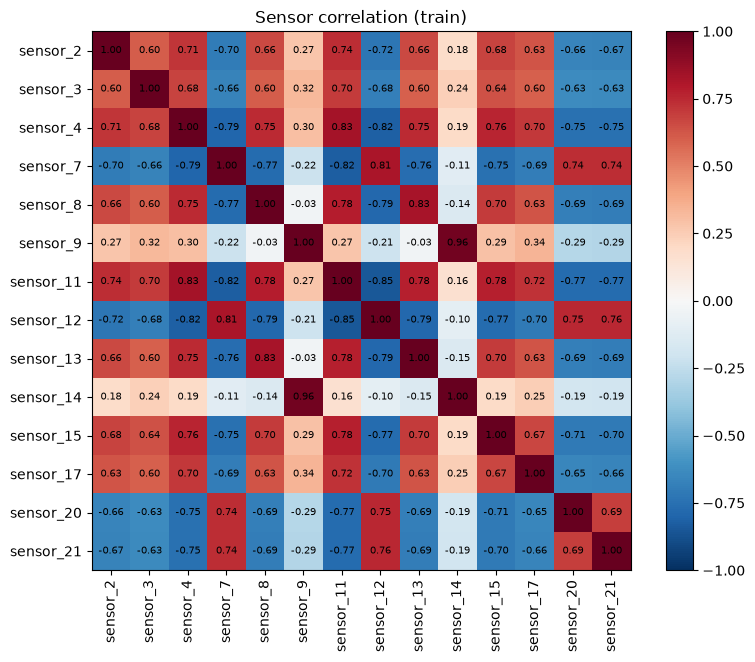

In [10]:
corr = train[SENSORS].corr()

fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(SENSORS)), SENSORS, rotation=90)
ax.set_yticks(range(len(SENSORS)), SENSORS)
for i in range(len(SENSORS)):
    for j in range(len(SENSORS)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
fig.colorbar(im, ax=ax)
ax.set_title("Sensor correlation (train)")
plt.show()

In [11]:
pairs = [
    (a, b, corr.loc[a, b])
    for i, a in enumerate(SENSORS)
    for b in SENSORS[i + 1:]
    if abs(corr.loc[a, b]) >= 0.8
]
pd.DataFrame(pairs, columns=["sensor_a", "sensor_b", "corr"]).sort_values("corr", key=abs, ascending=False).round(2)

,sensor_a,sensor_b,corr
5,sensor_9,sensor_14,0.96
6,sensor_11,sensor_12,-0.85
0,sensor_4,sensor_11,0.83
4,sensor_8,sensor_13,0.83
2,sensor_7,sensor_11,-0.82
1,sensor_4,sensor_12,-0.82
3,sensor_7,sensor_12,0.81


## 7. Operating condition

In [12]:
train[SETTINGS].describe()

,setting_1,setting_2,setting_3
count,20631.000000,20631.000000,20631.0
mean,-0.000009,0.000002,100.0
std,0.002187,0.000293,0.0
min,-0.008700,-0.000600,100.0
25%,-0.001500,-0.000200,100.0
50%,0.000000,0.000000,100.0
75%,0.001500,0.000300,100.0
max,0.008700,0.000600,100.0


`setting_1` and `setting_2` barely change and `setting_3` is constant, so FD001 has one operating condition and needs no per-condition normalisation.

## 8. Test file

Test engines are stopped before failure, so we see only part of each life. The true test RUL values are the test answers and are used only in notebook 05, so only their shape is shown here.

In [13]:
test_cycles = test.groupby("engine_id")["cycle"].max()
print(f"cycles seen per test engine: min {test_cycles.min()}, max {test_cycles.max()}")
print("load_test_rul().shape:", load_test_rul().shape)

cycles seen per test engine: min 31, max 303
load_test_rul().shape: (100, 2)
